# 🎯 Step 5: Threshold Selection and Business Cost Analysis

### **Objective:**
Transition from statistical evaluation (PR-AUC, ROC-AUC) to operational decision-making by evaluating the probability decision threshold on the **chronological validation partition** (May 20 – May 31, 2016; 20,539 appointments).

---

### **The Decision Dilemma:**
Machine learning models output continuous probabilities $P(\text{No-Show} = 1 \mid X) \in [0, 1]$.
An operational decision rule requires choosing a cutoff $\tau$:
$$\hat{Y} = \mathbb{I}(p \ge \tau)$$

* **Conventional Default Cutoff ($\tau = 0.50$):** Assumes symmetric penalties between false alarms and missed appointments. For this problem, a 0.50 cutoff produces very low recall because the vast majority of predicted scores concentrate below 0.50.
* **Business-Selected Cutoff ($\tau = 0.15$):** Tuned to the asymmetric costs of outpatient clinics, prioritizing high recall to prevent expensive idle provider capacity while managing staff outreach workload.

---

### **Illustrative Economic Parameters (Business Assumptions):**
> **Important Disclaimer:** These economic parameters are illustrative modeling assumptions for demonstrating cost-sensitive threshold selection, not actual hospital accounting figures or measured clinical outcomes. We make no empirical claim that outreach interventions guarantee no-show prevention in real-world practice.

* **Cost of an Unfilled Appointment ($C_{FN}$):** \$200 per missed appointment (idle physician slot, lost clinic capacity).
* **Cost of an Outreach Intervention ($C_{\text{intervene}}$):** \$10 per flagged/intervened patient. Both True Positives (TP) and False Positives (FP) receive the intervention.
* **Intervention Effectiveness ($r$):** 30% illustrative assumption (30% of actual no-shows who receive outreach are prevented; the remaining 70% still miss).

$$\text{Total Cost} = \text{Flagged Patients} \times \$10 + [\text{FN} + (1 - r) \cdot \text{TP}] \times \$200$$


## 1. Load Validation Predictions & Setup
Reusing the existing unweighted XGBoost validation probabilities and ground-truth labels.

In [1]:
import os
import ast
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 5)

# Robust path resolution
base_dir = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
possible_paths = [
    os.path.join(base_dir, '..', '..', 'data', 'processed'),
    os.path.join(base_dir, 'data', 'processed'),
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'data', 'processed'))
]
proc_dir = next((p for p in possible_paths if os.path.exists(p)), None)
if proc_dir is None:
    raise FileNotFoundError("Could not locate data/processed directory!")

preds_path = os.path.join(proc_dir, 'val_predictions_xgb_unweighted.csv')
summary_path = os.path.join(proc_dir, 'step5_threshold_comparison.csv')
json_path = os.path.join(proc_dir, 'step5_threshold_cost_analysis.json')

df_preds = pd.read_csv(preds_path)
y_val = df_preds['y_true'].values
probs_val = df_preds['y_prob_unweighted'].values

# Integrity assertions
assert len(y_val) == len(probs_val), "Mismatched predictions and label lengths!"
assert set(np.unique(y_val)) <= {0, 1}, "Labels must be binary!"
assert np.all(np.isfinite(probs_val)) and np.all((probs_val >= 0.0) & (probs_val <= 1.0)), "Invalid probabilities!"

actual_noshows = int(np.sum(y_val == 1))
actual_shows = int(np.sum(y_val == 0))
print(f"Validation Records:    {len(y_val):,} appointments")
print(f"Actual No-Shows (y=1): {actual_noshows:,} ({actual_noshows/len(y_val)*100:.2f}%)")
print(f"Actual Attended (y=0): {actual_shows:,} ({actual_shows/len(y_val)*100:.2f}%)")


Validation Records:    20,539 appointments
Actual No-Shows (y=1): 4,124 (20.08%)
Actual Attended (y=0): 16,415 (79.92%)


## 2. Threshold Performance Comparison Table
Comparing Conventional Default ($	au = 0.50$) vs Business-Selected ($	au = 0.15$).

In [2]:
df_comp = pd.read_csv(summary_path)
print("Step 5 Threshold Comparison Matrix (Validation Set):")
df_comp[[
    'threshold', 'recall', 'precision', 'f1_score', 'accuracy',
    'true_positives', 'false_positives', 'false_negatives', 'true_negatives',
    'flagged_count', 'pct_flagged', 'expected_cost', 'net_savings'
]]


Step 5 Threshold Comparison Matrix (Validation Set):


,threshold,recall,precision,f1_score,accuracy,true_positives,false_positives,false_negatives,true_negatives,flagged_count,pct_flagged,expected_cost,net_savings
0,0.50,0.0347,0.4719,0.0646,0.7984,143,160,3981,16255,303,1.48,819250.0,5550.0
1,0.15,0.9362,0.2909,0.4438,0.5289,3861,9413,263,7002,13274,64.63,725880.0,98920.0


## 3. Confusion Matrix Visualizations Side-by-Side

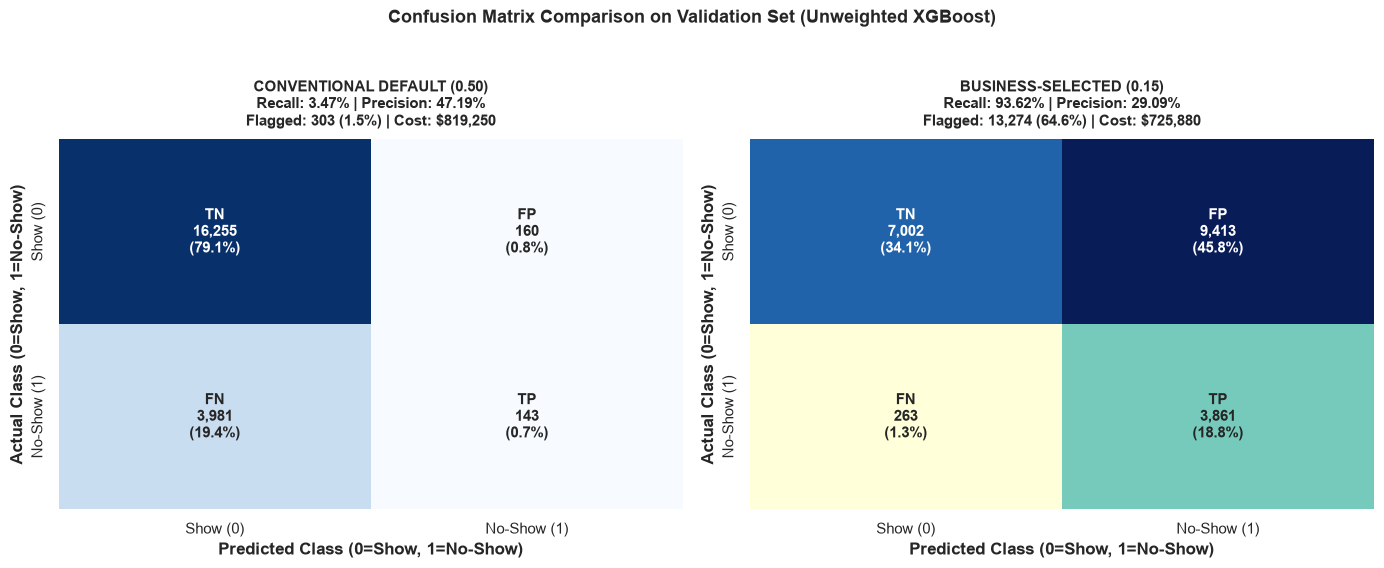

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

thresholds = [0.50, 0.15]
palettes = ['Blues', 'YlGnBu']

for idx, t in enumerate(thresholds):
    row = df_comp[df_comp['threshold'] == t].iloc[0]
    cm_raw = row['confusion_matrix']
    cm = np.array(ast.literal_eval(cm_raw)) if isinstance(cm_raw, str) else np.array(cm_raw)
    tn, fp = cm[0]
    fn, tp = cm[1]
    
    labels = [
        [f"TN\n{tn:,}\n({tn/cm.sum()*100:.1f}%)", f"FP\n{fp:,}\n({fp/cm.sum()*100:.1f}%)"],
        [f"FN\n{fn:,}\n({fn/cm.sum()*100:.1f}%)", f"TP\n{tp:,}\n({tp/cm.sum()*100:.1f}%)"]
    ]
    
    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap=palettes[idx],
        cbar=False,
        ax=axes[idx],
        annot_kws={"fontsize": 11, "fontweight": "bold"}
    )
    
    tag = "CONVENTIONAL DEFAULT (0.50)" if t == 0.50 else "BUSINESS-SELECTED (0.15)"
    axes[idx].set_title(
        f"{tag}\nRecall: {row['recall']*100:.2f}% | Precision: {row['precision']*100:.2f}%\n"
        f"Flagged: {row['flagged_count']:,} ({row['pct_flagged']:.1f}%) | Cost: ${row['expected_cost']:,.0f}",
        fontsize=11,
        fontweight='bold',
        pad=10
    )
    axes[idx].set_xlabel("Predicted Class (0=Show, 1=No-Show)", fontweight='bold')
    axes[idx].set_ylabel("Actual Class (0=Show, 1=No-Show)", fontweight='bold')
    axes[idx].set_xticklabels(['Show (0)', 'No-Show (1)'])
    axes[idx].set_yticklabels(['Show (0)', 'No-Show (1)'])

plt.suptitle("Confusion Matrix Comparison on Validation Set (Unweighted XGBoost)", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 4. Economic Cost Breakdown & Workload Trade-Offs

### **Why Threshold 0.15 Outperforms 0.50 Economically:**
* **At $\tau = 0.50$:** The model flags only 303 appointments (1.48% workload). Recall is approximately **3.47%**, identifying only 143 no-shows and missing approximately **96.53%** (3,981 no-shows). Total expected clinic cost remains **\$819,250**, delivering only \$5,550 in estimated savings over no intervention.
* **At $\tau = 0.15$:** The model flags 13,274 appointments (64.63% workload). Recall jumps to **93.62%** (3,861 no-shows caught, only 263 missed). Under 30% outreach efficacy, this delivers **\$725,880** in expected cost—an estimated savings of **\$98,920** over no intervention and **\$93,370 (11.40% lower cost)** compared to the default threshold.


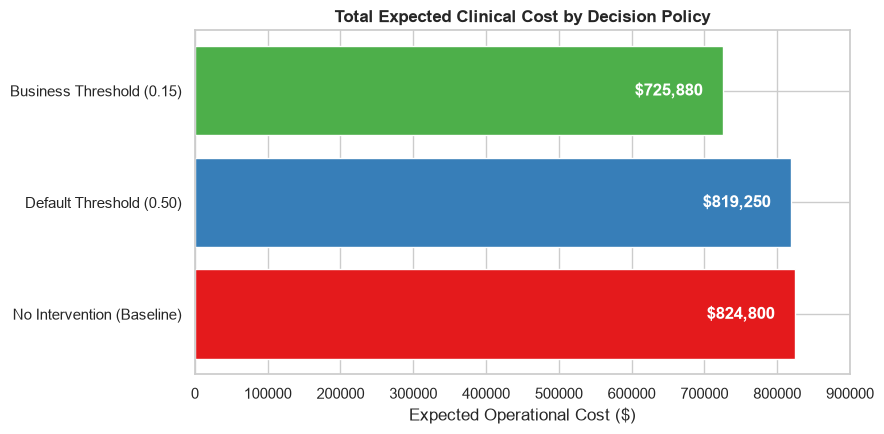

Cost Comparison Table:
        Operational Policy  Total Expected Cost ($)  Estimated Savings vs Baseline ($)
No Intervention (Baseline)                 824800.0                                0.0
  Default Threshold (0.50)                 819250.0                             5550.0
 Business Threshold (0.15)                 725880.0                            98920.0


In [4]:
# Derive baseline dynamically from validation ground truth
baseline_cost = int(np.sum(y_val == 1)) * 200
cost_50 = df_comp[df_comp['threshold'] == 0.50]['expected_cost'].values[0]
cost_15 = df_comp[df_comp['threshold'] == 0.15]['expected_cost'].values[0]

cost_comparison_data = pd.DataFrame({
    'Operational Policy': ['No Intervention (Baseline)', 'Default Threshold (0.50)', 'Business Threshold (0.15)'],
    'Total Expected Cost ($)': [baseline_cost, cost_50, cost_15],
    'Estimated Savings vs Baseline ($)': [0, baseline_cost - cost_50, baseline_cost - cost_15]
})

plt.figure(figsize=(9, 4.5))
bars = plt.barh(
    cost_comparison_data['Operational Policy'],
    cost_comparison_data['Total Expected Cost ($)'],
    color=['#e41a1c', '#377eb8', '#4daf4a']
)
plt.title("Total Expected Clinical Cost by Decision Policy", fontsize=12, fontweight='bold')
plt.xlabel("Expected Operational Cost ($)")
for bar in bars:
    w = bar.get_width()
    plt.text(w - 75000, bar.get_y() + bar.get_height()/2, f"${w:,.0f}", ha='center', va='center', color='white', fontweight='bold')
plt.xlim(0, 900000)
plt.tight_layout()
plt.show()

print("Cost Comparison Table:")
print(cost_comparison_data.to_string(index=False))


## 5. Strategic Interpretation & Trade-Off Analysis

### **Key Analytical Findings:**
1. **Threshold Interpretation:**  
   Under the illustrative business assumptions, the theoretical decision threshold is approximately **0.167**, assuming calibrated probabilities and uniform intervention effectiveness and costs. The empirical analysis identifies **0.15** as the lowest-cost candidate among the thresholds evaluated.
2. **Conventional Default vs Business Decision:**  
   0.50 is merely a conventional default cutoff, not necessarily the appropriate cutoff for this business problem. The low recall at 0.50 (3.47%) is due to the distribution of model scores relative to the chosen cutoff, rather than an inherent failure of model discrimination.
3. **Trade-Offs of Lowering Threshold:**  
   Lowering the threshold to 0.15 drives recall from 3.47% to 93.62%, but decreases precision from 47.19% to 29.09% and increases intervention volume to 13,274 contacts (64.63% of appointments). The operational decision requires balancing staff outreach capacity against the severe financial penalty of unfilled appointments.
4. **Validation Limitation:**  
   The threshold and associated cost were selected and evaluated using the same validation dataset. Therefore, these figures are validation-based selection results under illustrative assumptions, not unbiased estimates of real-world savings.

---

### 🚀 Next Primary Milestone: Step 6 — SHAP-Based Model Interpretability
With the operational decision threshold established on validation data, our next milestone is **SHAP (SHapley Additive exPlanations)** to uncover the clinical and operational drivers behind individual predictions.

*(Note on Subgroup & June Evaluation: Subgroup fairness analysis can be conducted as an optional extension. Furthermore, June 2016 predictions were previously exposed during earlier exploratory model comparisons, so June serves as an exploratory chronological reference rather than a pristine, untouched test set).*
